<a href="https://colab.research.google.com/github/MNawfal24/MachineLearning/blob/main/Minggu11/MNawfalMA_JS11_P04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from sklearn.datasets import fetch_lfw_people

# Unduh dataset dengan filter minimal 60 citra per orang
faces = fetch_lfw_people(min_faces_per_person=60)
print('Target Names:')
print(faces.target_names)
print(f'\nJumlah Kelas: {len(faces.target_names)}')
print(f'Dimensi Citra: {faces.images.shape}')

Target Names:
['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']

Jumlah Kelas: 8
Dimensi Citra: (1348, 62, 47)


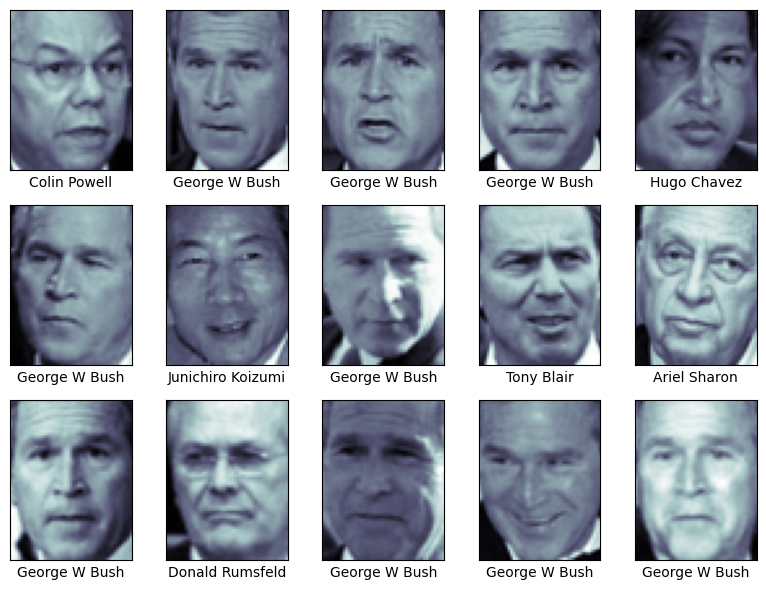

In [2]:
import matplotlib.pyplot as plt

# Tampilkan contoh wajah
fig, ax = plt.subplots(3, 5, figsize=(8, 6))
for i, axi in enumerate(ax.flat):
    if i < len(faces.images):
        axi.imshow(faces.images[i], cmap='bone')
        axi.set(xticks=[], yticks=[],
                xlabel=faces.target_names[faces.target[i]])
plt.tight_layout()
plt.show()

In [3]:
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline

# PCA untuk reduksi dimensi menjadi 150 komponen utama (eigenfaces)
pca = PCA(n_components=150, whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

print('Pipeline berhasil dibuat:')
print(model)

Pipeline berhasil dibuat:
Pipeline(steps=[('pca', PCA(n_components=150, random_state=42, whiten=True)),
                ('svc', SVC(class_weight='balanced'))])


In [4]:
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target,
                                                random_state=42)

print(f'Jumlah Data Training: {len(Xtrain)} citra (75%)')
print(f'Jumlah Data Testing : {len(Xtest)} citra (25%)')

Jumlah Data Training: 1011 citra (75%)
Jumlah Data Testing : 337 citra (25%)


In [5]:
from sklearn.model_selection import GridSearchCV

# Tentukan grid parameter untuk C dan gamma pada SVC
param_grid = {
    'svc__C': [1, 5, 10, 50],
    'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]
}

grid = GridSearchCV(model, param_grid)
grid.fit(Xtrain, ytrain)

print('Proses Grid Search selesai!')
print(f'Best Parameters: {grid.best_params_}')
print(f'Best CV Score  : {grid.best_score_:.4f}')

Proses Grid Search selesai!
Best Parameters: {'svc__C': 5, 'svc__gamma': 0.001}
Best CV Score  : 0.8289


In [6]:
from sklearn.metrics import classification_report

best_model = grid.best_estimator_
yfit = best_model.predict(Xtest)

print('Classification Report:')
print(classification_report(ytest, yfit,
                            target_names=faces.target_names))

Classification Report:
                   precision    recall  f1-score   support

     Ariel Sharon       0.65      0.87      0.74        15
     Colin Powell       0.83      0.88      0.86        68
  Donald Rumsfeld       0.70      0.84      0.76        31
    George W Bush       0.97      0.80      0.88       126
Gerhard Schroeder       0.76      0.83      0.79        23
      Hugo Chavez       0.93      0.70      0.80        20
Junichiro Koizumi       0.86      1.00      0.92        12
       Tony Blair       0.82      0.98      0.89        42

         accuracy                           0.85       337
        macro avg       0.82      0.86      0.83       337
     weighted avg       0.86      0.85      0.85       337



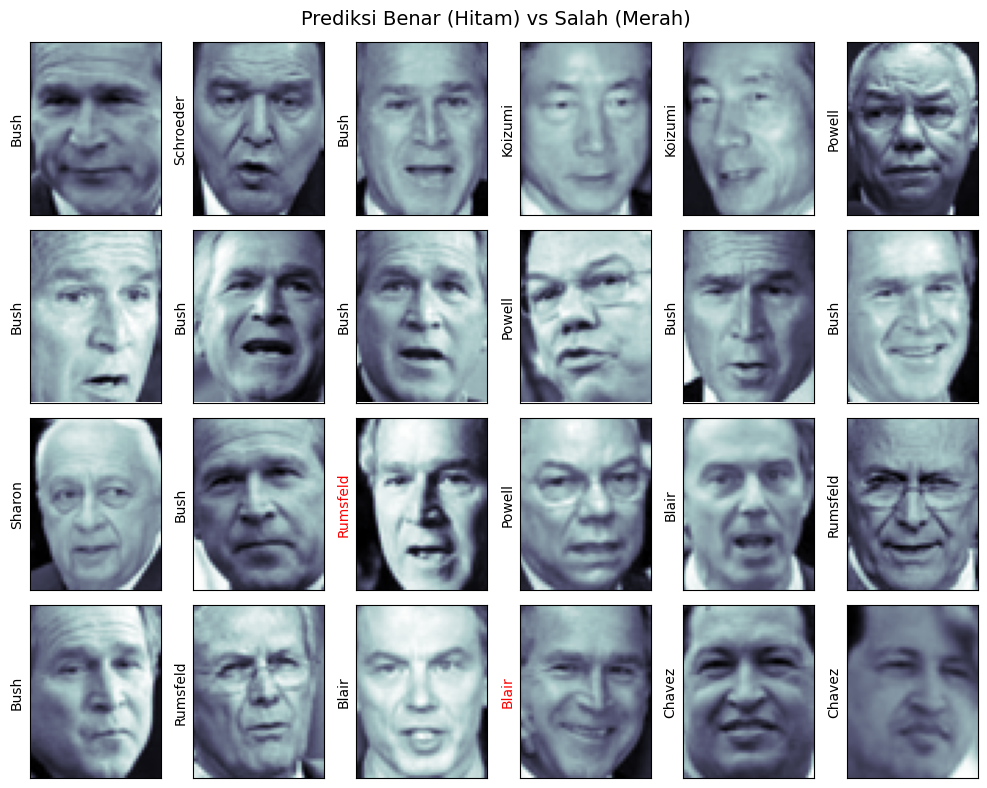

In [7]:
# Visualisasi beberapa hasil prediksi
fig, ax = plt.subplots(4, 6, figsize=(10, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    is_correct = (yfit[i] == ytest[i])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if is_correct else 'red')
fig.suptitle('Prediksi Benar (Hitam) vs Salah (Merah)', size=14)
plt.tight_layout()
plt.show()

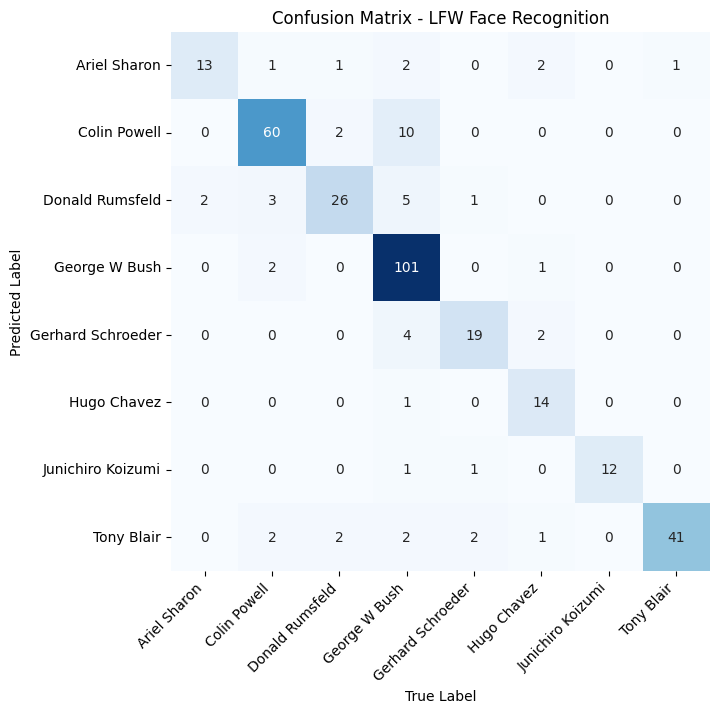

In [8]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot confusion matrix heatmap
mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(9, 7))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names,
            yticklabels=faces.target_names,
            cmap='Blues')
plt.xlabel('True Label')
plt.ylabel('Predicted Label')
plt.title('Confusion Matrix - LFW Face Recognition')
plt.xticks(rotation=45, ha='right')
plt.show()